In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [5]:
print(df.isnull().sum())

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [6]:
print(df["diagnosis"].value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64


In [7]:
# Remove unnecessary columns
df = df.drop(columns=["id", "Unnamed: 32"])

# Convert diagnosis into numerical labels
df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print("Cleaned dataset shape:", df.shape)
display(df.head())

Cleaned dataset shape: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [8]:
# Separate input features and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (569, 30)
Target: (569,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (455, 30)
Testing features: (114, 30)
Training labels: (455,)
Testing labels: (114,)


In [10]:
print("Training completed preparation successfully!")
print("Number of training samples:", len(X_train))
print("Number of testing samples:", len(X_test))
print("Number of input features:", X_train.shape[1])

Training completed preparation successfully!
Number of training samples: 455
Number of testing samples: 114
Number of input features: 30


## 1. Logistic Regression

Logistic Regression is a supervised machine learning classification algorithm. It predicts the probability that an input belongs to a particular class. In this assignment, it predicts whether a breast tissue sample is Benign or Malignant based on 30 input features.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [12]:
# Create the model
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
# Predict the classes
y_pred_lr = lr_model.predict(X_test)

# Predict class probabilities
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

print("Actual labels:", y_test.to_numpy()[:10])
print("Predicted labels:", y_pred_lr[:10])
print("Predicted probabilities:", y_prob_lr[:10])

Actual labels: [0 1 0 1 0 0 1 0 0 0]
Predicted labels: [0 1 0 1 1 0 1 0 0 0]
Predicted probabilities: [3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


In [14]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Calculate evaluation metrics
acc_lr = accuracy_score(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)
pre_lr = precision_score(y_test, y_pred_lr, zero_division=0)
rec_lr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)
mcc_lr = matthews_corrcoef(y_test, y_pred_lr)

# Display results
print("Logistic Regression Evaluation")
print("--------------------------------")
print(f"Accuracy  : {acc_lr:.4f}")
print(f"AUC Score : {auc_lr:.4f}")
print(f"Precision : {pre_lr:.4f}")
print(f"Recall    : {rec_lr:.4f}")
print(f"F1 Score  : {f1_lr:.4f}")
print(f"MCC Score : {mcc_lr:.4f}")

Logistic Regression Evaluation
--------------------------------
Accuracy  : 0.9649
AUC Score : 0.9960
Precision : 0.9750
Recall    : 0.9286
F1 Score  : 0.9512
MCC Score : 0.9245


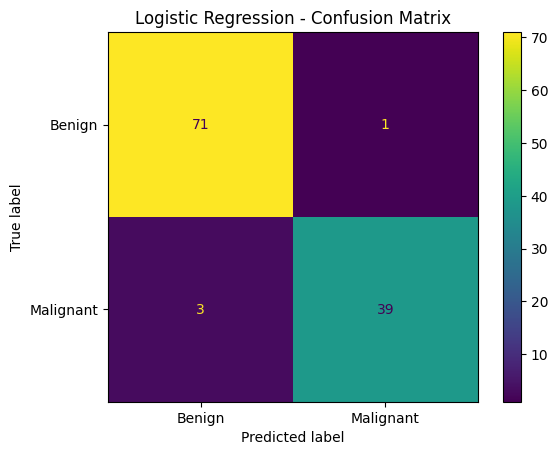

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [16]:
results = []

results.append({
    "Model": "Logistic Regression",
    "Accuracy": acc_lr,
    "AUC": auc_lr,
    "Precision": pre_lr,
    "Recall": rec_lr,
    "F1 Score": f1_lr,
    "MCC": mcc_lr
})

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.996,0.975,0.9286,0.9512,0.9245


## 2. Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm that classifies data using a sequence of decision rules. It splits the dataset based on feature values and predicts the class at the final leaf node.

In [17]:
from sklearn.tree import DecisionTreeClassifier

In [18]:
# Create the model
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [19]:
# Predict the classes
y_pred_dt = dt_model.predict(X_test)

# Predict class probabilities
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("Actual labels:", y_test.to_numpy()[:10])
print("Predicted labels:", y_pred_dt[:10])
print("Predicted probabilities:", y_prob_dt[:10])

Actual labels: [0 1 0 1 0 0 1 0 0 0]
Predicted labels: [0 1 1 1 0 0 1 0 0 0]
Predicted probabilities: [0. 1. 1. 1. 0. 0. 1. 0. 0. 0.]


In [20]:
# Calculate evaluation metrics
acc_dt = accuracy_score(y_test, y_pred_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)
pre_dt = precision_score(y_test, y_pred_dt, zero_division=0)
rec_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)
mcc_dt = matthews_corrcoef(y_test, y_pred_dt)

# Display results
print("Decision Tree Evaluation")
print("-------------------------")
print(f"Accuracy  : {acc_dt:.4f}")
print(f"AUC Score : {auc_dt:.4f}")
print(f"Precision : {pre_dt:.4f}")
print(f"Recall    : {rec_dt:.4f}")
print(f"F1 Score  : {f1_dt:.4f}")
print(f"MCC Score : {mcc_dt:.4f}")

Decision Tree Evaluation
-------------------------
Accuracy  : 0.9298
AUC Score : 0.9246
Precision : 0.9048
Recall    : 0.9048
F1 Score  : 0.9048
MCC Score : 0.8492


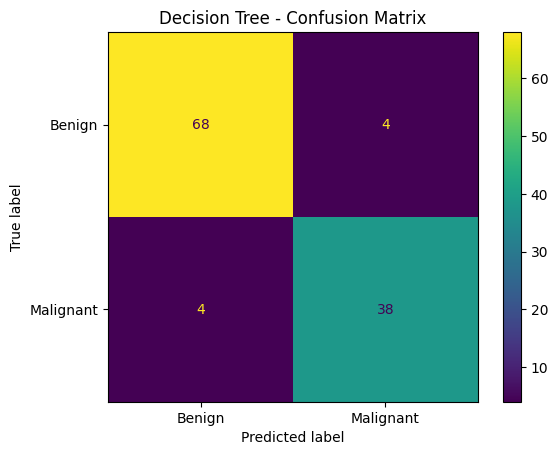

In [21]:
# Calculate the confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [22]:
# Store Decision Tree results
results.append({
    "Model": "Decision Tree",
    "Accuracy": acc_dt,
    "AUC": auc_dt,
    "Precision": pre_dt,
    "Recall": rec_dt,
    "F1 Score": f1_dt,
    "MCC": mcc_dt
})

# Display the comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492


## 3. K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised machine learning classification algorithm. It classifies a new sample by examining the classes of its nearest training samples. In this assignment, KNN predicts whether a breast tissue sample is Benign or Malignant.

In [23]:
from sklearn.neighbors import KNeighborsClassifier

In [24]:
# Create the KNN model
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [25]:
# Predict the classes
y_pred_knn = knn_model.predict(X_test)

# Predict probabilities for the Malignant class
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

print("Actual labels:", y_test.to_numpy()[:10])
print("Predicted labels:", y_pred_knn[:10])
print("Predicted probabilities:", y_prob_knn[:10])

Actual labels: [0 1 0 1 0 0 1 0 0 0]
Predicted labels: [0 1 0 0 0 0 1 0 0 0]
Predicted probabilities: [0.  1.  0.  0.2 0.  0.  0.8 0.  0.  0. ]


In [26]:
# Calculate evaluation metrics
acc_knn = accuracy_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)
pre_knn = precision_score(y_test, y_pred_knn, zero_division=0)
rec_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)
mcc_knn = matthews_corrcoef(y_test, y_pred_knn)

# Display results
print("KNN Evaluation")
print("-------------------------")
print(f"Accuracy  : {acc_knn:.4f}")
print(f"AUC Score : {auc_knn:.4f}")
print(f"Precision : {pre_knn:.4f}")
print(f"Recall    : {rec_knn:.4f}")
print(f"F1 Score  : {f1_knn:.4f}")
print(f"MCC Score : {mcc_knn:.4f}")

KNN Evaluation
-------------------------
Accuracy  : 0.9561
AUC Score : 0.9823
Precision : 0.9744
Recall    : 0.9048
F1 Score  : 0.9383
MCC Score : 0.9058


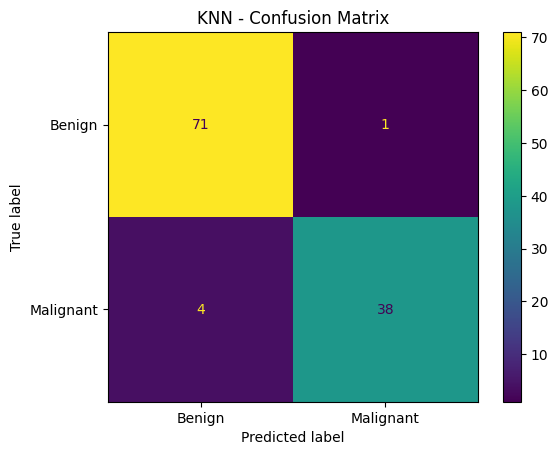

In [27]:
# Calculate the confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("KNN - Confusion Matrix")
plt.show()

In [28]:
# Store KNN results
results.append({
    "Model": "KNN",
    "Accuracy": acc_knn,
    "AUC": auc_knn,
    "Precision": pre_knn,
    "Recall": rec_knn,
    "F1 Score": f1_knn,
    "MCC": mcc_knn
})

# Display the comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058


## 4. Gaussian Naive Bayes

Gaussian Naive Bayes is a supervised machine learning classification algorithm based on Bayes' theorem. It assumes that the features follow a Gaussian (normal) distribution within each class. In this assignment, it predicts whether a breast tissue sample is Benign or Malignant.

In [29]:
from sklearn.naive_bayes import GaussianNB

In [30]:
# Create the model
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully!")

Gaussian Naive Bayes model trained successfully!


In [31]:
# Predict the classes
y_pred_nb = nb_model.predict(X_test)

# Predict probabilities for the Malignant class
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

print("Actual labels:", y_test.to_numpy()[:10])
print("Predicted labels:", y_pred_nb[:10])
print("Predicted probabilities:", y_prob_nb[:10])

Actual labels: [0 1 0 1 0 0 1 0 0 0]
Predicted labels: [0 1 0 0 0 0 0 0 0 0]
Predicted probabilities: [3.75512810e-15 1.00000000e+00 1.58885749e-02 3.20224578e-03
 2.92922538e-10 1.00665130e-02 2.64632029e-01 8.64760887e-11
 1.19101759e-15 1.14531854e-12]


In [32]:
# Calculate evaluation metrics
acc_nb = accuracy_score(y_test, y_pred_nb)
auc_nb = roc_auc_score(y_test, y_prob_nb)
pre_nb = precision_score(y_test, y_pred_nb, zero_division=0)
rec_nb = recall_score(y_test, y_pred_nb, zero_division=0)
f1_nb = f1_score(y_test, y_pred_nb, zero_division=0)
mcc_nb = matthews_corrcoef(y_test, y_pred_nb)

# Display results
print("Gaussian Naive Bayes Evaluation")
print("--------------------------------")
print(f"Accuracy  : {acc_nb:.4f}")
print(f"AUC Score : {auc_nb:.4f}")
print(f"Precision : {pre_nb:.4f}")
print(f"Recall    : {rec_nb:.4f}")
print(f"F1 Score  : {f1_nb:.4f}")
print(f"MCC Score : {mcc_nb:.4f}")

Gaussian Naive Bayes Evaluation
--------------------------------
Accuracy  : 0.9386
AUC Score : 0.9934
Precision : 1.0000
Recall    : 0.8333
F1 Score  : 0.9091
MCC Score : 0.8715


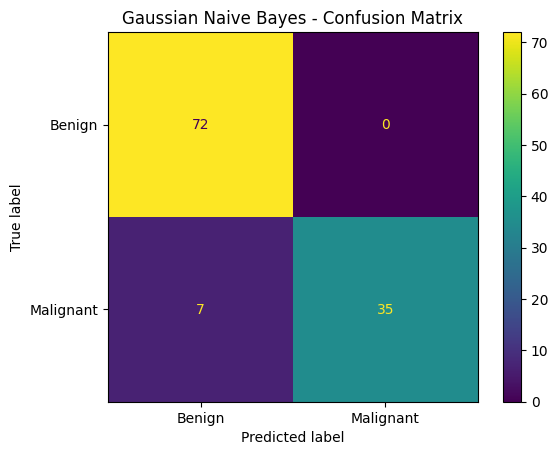

In [33]:
# Calculate the confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()

In [34]:
# Store Naive Bayes results
results.append({
    "Model": "Gaussian Naive Bayes",
    "Accuracy": acc_nb,
    "AUC": auc_nb,
    "Precision": pre_nb,
    "Recall": rec_nb,
    "F1 Score": f1_nb,
    "MCC": mcc_nb
})

# Display the comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Gaussian Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715


## 5. Support Vector Machine (SVM)

Support Vector Machine is a supervised machine learning classification algorithm that finds a decision boundary separating different classes. It aims to maximize the margin between the classes. In this assignment, SVM predicts whether a breast tissue sample is Benign or Malignant.

In [35]:
from sklearn.svm import SVC

In [36]:
# Create the SVM model
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", probability=True, random_state=42)
)

# Train the model
svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [37]:
# Predict the classes
y_pred_svm = svm_model.predict(X_test)

# Predict probabilities for the Malignant class
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

print("Actual labels:", y_test.to_numpy()[:10])
print("Predicted labels:", y_pred_svm[:10])
print("Predicted probabilities:", y_prob_svm[:10])

Actual labels: [0 1 0 1 0 0 1 0 0 0]
Predicted labels: [0 1 0 0 0 0 1 0 0 0]
Predicted probabilities: [1.62722191e-03 9.99993901e-01 6.16211841e-02 4.41768281e-01
 1.04012968e-01 2.71682666e-02 9.10809484e-01 3.19886190e-03
 8.55882557e-04 3.65284338e-03]


In [38]:
# Calculate evaluation metrics
acc_svm = accuracy_score(y_test, y_pred_svm)
auc_svm = roc_auc_score(y_test, y_prob_svm)
pre_svm = precision_score(y_test, y_pred_svm, zero_division=0)
rec_svm = recall_score(y_test, y_pred_svm, zero_division=0)
f1_svm = f1_score(y_test, y_pred_svm, zero_division=0)
mcc_svm = matthews_corrcoef(y_test, y_pred_svm)

# Display results
print("Support Vector Machine Evaluation")
print("---------------------------------")
print(f"Accuracy  : {acc_svm:.4f}")
print(f"AUC Score : {auc_svm:.4f}")
print(f"Precision : {pre_svm:.4f}")
print(f"Recall    : {rec_svm:.4f}")
print(f"F1 Score  : {f1_svm:.4f}")
print(f"MCC Score : {mcc_svm:.4f}")

Support Vector Machine Evaluation
---------------------------------
Accuracy  : 0.9737
AUC Score : 0.9947
Precision : 1.0000
Recall    : 0.9286
F1 Score  : 0.9630
MCC Score : 0.9442


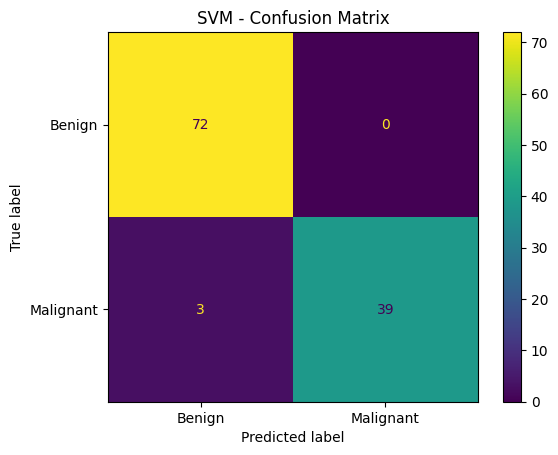

In [39]:
# Calculate the confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("SVM - Confusion Matrix")
plt.show()

In [40]:
# Store SVM results
results.append({
    "Model": "Support Vector Machine",
    "Accuracy": acc_svm,
    "AUC": auc_svm,
    "Precision": pre_svm,
    "Recall": rec_svm,
    "F1 Score": f1_svm,
    "MCC": mcc_svm
})

# Display the comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Gaussian Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


In [41]:
print("Total models evaluated:", len(results_df))

display(results_df.round(4))

Total models evaluated: 5


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Gaussian Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


In [42]:
import os
import joblib

# Create the model folder
os.makedirs("model", exist_ok=True)

# Save all five models
joblib.dump(lr_model, "model/logistic_regression.joblib")
joblib.dump(dt_model, "model/decision_tree.joblib")
joblib.dump(knn_model, "model/knn.joblib")
joblib.dump(nb_model, "model/naive_bayes.joblib")
joblib.dump(svm_model, "model/svm.joblib")

print("All five models saved successfully!")

All five models saved successfully!


In [43]:
import os

print(os.listdir("model"))

['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'svm.joblib']


In [42]:
# Create the test dataset
test_df = X_test.copy()
test_df["diagnosis"] = y_test

# Save the test dataset
test_df.to_csv("test_data.csv", index=False)

print("Test dataset created successfully!")
print("Dataset shape:", test_df.shape)

display(test_df.head())

Test dataset created successfully!
Dataset shape: (114, 31)


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,diagnosis
120,11.41,10.82,73.34,403.3,0.09373,0.06685,0.03512,0.02623,0.1667,0.06113,...,15.97,83.74,510.5,0.1548,0.2390,0.21020,0.08958,0.3016,0.08523,0
250,20.94,23.56,138.90,1364.0,0.10070,0.16060,0.27120,0.13100,0.2205,0.05898,...,27.00,165.30,2010.0,0.1211,0.3172,0.69910,0.21050,0.3126,0.07849,1
375,16.17,16.07,106.30,788.5,0.09880,0.14380,0.06651,0.05397,0.1990,0.06572,...,19.14,113.10,861.5,0.1235,0.2550,0.21140,0.12510,0.3153,0.08960,0
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,30.86,109.50,826.4,0.1431,0.3026,0.31940,0.15650,0.2718,0.09353,1
455,13.38,30.72,86.34,557.2,0.09245,0.07426,0.02819,0.03264,0.1375,0.06016,...,41.61,96.69,705.6,0.1172,0.1421,0.07003,0.07763,0.2196,0.07675,0
